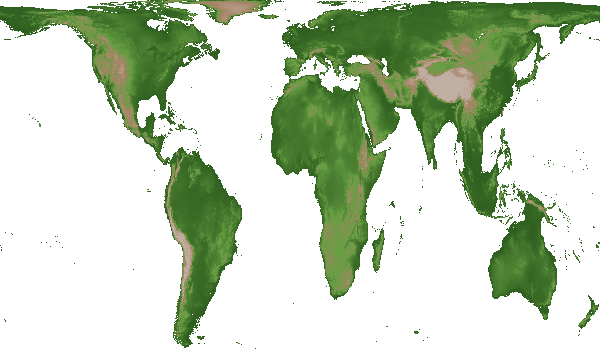

Image dimensions: 600x351 pixels


In [7]:
# first load image and show with pil
from PIL import Image
from IPython.display import display

# Load the image
image_path = "ch1_map.png"
image = Image.open(image_path)
image = image.convert("RGBA")  # Ensure it's in RGBA format
# Display the image
display(image)
# print dimensions of the image
print(f"Image dimensions: {image.size[0]}x{image.size[1]} pixels")


Binary matrix shape: (351, 600)
First 10 rows of the binary matrix:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]]


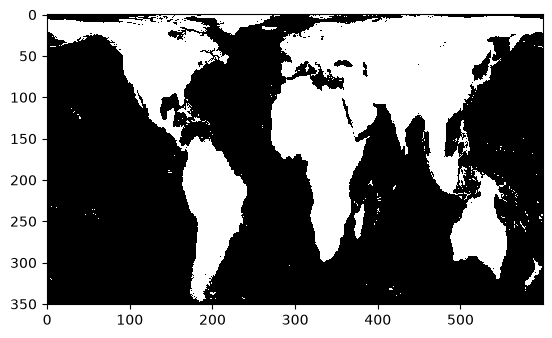

In [8]:
# make a matrix with similar dimensions such that all white pixels are 0 and all other pixels are 1
import numpy as np
# Convert the image to a numpy array
image_array = np.array(image)
# Create a mask where white pixels are 0 and all other pixels are 1
mask = np.all(image_array[:, :, :3] == [255, 255, 255], axis=-1)
# Convert the mask to a binary matrix
binary_matrix = np.where(mask, 0, 1)
# Print the shape of the binary matrix
print(f"Binary matrix shape: {binary_matrix.shape}")
# Print the first 10 rows of the binary matrix
print("First 10 rows of the binary matrix:")
print(binary_matrix[:10])
# show as black white image
import matplotlib.pyplot as plt
plt.imshow(binary_matrix, cmap='gray', interpolation='nearest')

In [10]:
# Boolean land mask: True = land, False = sea. Indexed as LAND[y, x] (row, column).
LAND = binary_matrix.astype(bool)

# Background map as a plain RGB array, loaded once so it isn't re-read every frame.
BG = np.array(Image.open("ch1_map.png").convert("RGB"))

# Terrain suitability and regions
The map colours encode elevation: green is lowland, brown/beige is mountains (Tibet, Andes, Ethiopian highlands).
We turn this into a suitability score per cell, which later slows down hatching in the mountains.

We also define two regions (Europe and Asia) as boxes on the land mask, so we can check whether any of their cells is occupied.

* Which barriers do you expect to slow the route to Asia? And to Europe?

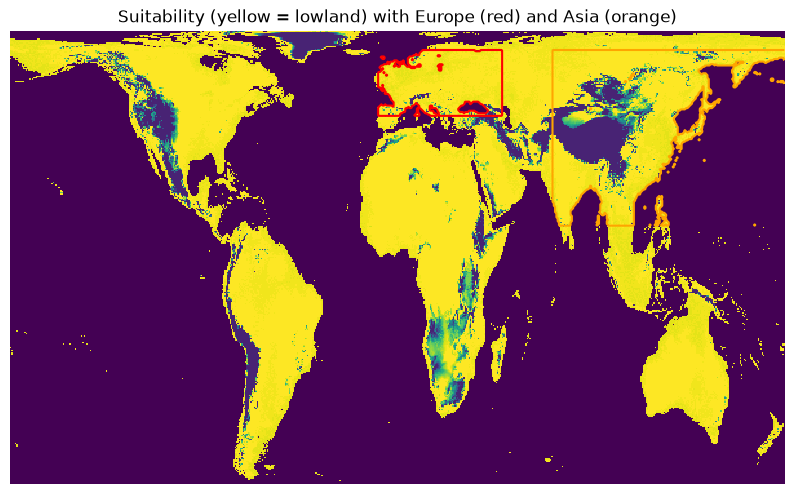

In [11]:
# --- Terrain suitability from the map itself ---
# Work with floats so the subtraction below can go negative (uint8 would wrap around)
rgb = BG.astype(float)

# Lowlands are green (G much larger than R, ~50), mountains are brown/beige (G about equal to or below R)
greenness = rgb[:, :, 1] - rgb[:, :, 0]

# Scale to 0-1: lowland ~1, mountains get the floor of 0.1 (slow, but not impassable)
SUITABILITY = np.clip(greenness / 50, 0.1, 1.0)

# Sea is never suitable (agents already can't go there, this just keeps the array clean)
SUITABILITY[~LAND] = 0.0

# --- Regions, indexed [y, x] like LAND (y = row, 0 at the top) ---
# Europe: west of the Black Sea, north of the Mediterranean and Turkey
EUROPE = np.zeros_like(LAND)
EUROPE[15:66, 285:381] = True
EUROPE &= LAND   # only count land cells

# Asia: east of Iran (India, China, Siberia); the Middle East is left out on purpose,
# otherwise "Asia" is reached almost immediately via Sinai
ASIA = np.zeros_like(LAND)
ASIA[15:151, 420:600] = True
ASIA &= LAND

# Show suitability with the two regions outlined, to check the boxes
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(SUITABILITY, cmap="viridis", interpolation="nearest")
ax.contour(EUROPE, levels=[0.5], colors="red")   # outline of Europe
ax.contour(ASIA, levels=[0.5], colors="orange")  # outline of Asia
ax.set_title("Suitability (yellow = lowland) with Europe (red) and Asia (orange)")
ax.axis("off")
plt.show()

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import mesa
from mesa.discrete_space import CellAgent, OrthogonalMooreGrid
from mesa.visualization import SolaraViz, make_plot_component, make_space_component

class DispersalAgent(CellAgent):
    def __init__(self, model, cell, growth_rate):
        super().__init__(model)
        self.cell = cell
        self.growth_rate = growth_rate
        # mark cell as taken and add to frontier (item 3)
        x, y = cell.coordinate
        model.occupied[y, x] = True
        model.frontier.add(self)

    def hatch(self):  # 4 spaces in, same level as __init__
        # free land neighbours only
        options = [c for c in self.cell.neighborhood.cells
                   if LAND[c.coordinate[1], c.coordinate[0]]
                   and not self.model.occupied[c.coordinate[1], c.coordinate[0]]]
        # enclosed: drop from frontier for good
        if not options:
            self.model.frontier.discard(self)
            return

        # NEW: rare long-distance jump (only in the asymmetric version).
        # Uses up this agent's turn, whether or not the jump lands somewhere free.
        if self.model.asymmetry and self.random.random() < self.model.jump_prob:
            self.jump()
            return

        # pick the target cell first, so its terrain can set the probability
        target = self.random.choice(options)
        p = self.growth_rate
        # NEW: terrain makes hatching less likely into mountains (asymmetric version only)
        if self.model.asymmetry:
            p = p * SUITABILITY[target.coordinate[1], target.coordinate[0]]

        # hatch with probability p
        if self.random.random() < p:
            DispersalAgent(self.model, target, self.growth_rate)

    def jump(self):
        """Found a new colony at a random cell up to jump_distance away (can cross narrow water)."""
        width, height = self.model.grid.dimensions
        x, y = self.cell.coordinate
        d = self.model.jump_distance
        # random offset in a square around the agent; % wraps around like the torus grid
        tx = (x + self.random.randint(-d, d)) % width
        ty = (y + self.random.randint(-d, d)) % height
        # only land on free land; otherwise the jump fails (lost in the sea / already taken)
        if LAND[ty, tx] and not self.model.occupied[ty, tx]:
            DispersalAgent(self.model, self.model.grid[(tx, ty)], self.growth_rate)

# NEW: model-level reporters for the datacollector (same style as maxdistance in the full func model)
def europe_occupied(model):
    # True as soon as any Europe cell holds an agent
    return bool(model.occupied[EUROPE].any())

def asia_occupied(model):
    # True as soon as any Asia cell holds an agent
    return bool(model.occupied[ASIA].any())

def n_agents(model):
    # number of agents = number of occupied cells
    return int(model.occupied.sum())

class DispersalModel(mesa.Model):
    """A model with a grid of cells and agents that can occupy them."""

    def __init__(self, n=10, width=600, height=351, seed=None, growth_rate=0.1,
                 asymmetry=False, jump_prob=0.0005, jump_distance=15):
        # width/height must match the image (600 x 351), or indexing LAND fails.
        """Initialize the model instance

        Args:
            n (int): Number of agents to create.
            width (int): Width of the grid.
            height (int): Height of the grid.
            seed (int, optional): Random seed for reproducibility.
            growth_rate (float): Probability per step that a frontier agent hatches.
            asymmetry (bool): Switch terrain suitability + long-distance jumps on/off.
            jump_prob (float): Probability per step that a frontier agent attempts a jump.
            jump_distance (int): Maximum jump distance in cells (in x and y).
        """
        super().__init__(seed=seed)
        self.num_agents = n
        # NEW: store the switch and jump settings so agents can read them via self.model
        self.asymmetry = asymmetry
        self.jump_prob = jump_prob
        self.jump_distance = jump_distance
        self.grid = OrthogonalMooreGrid(dimensions=(width, height), torus=True, random=self.random)
        # Occupancy array, same shape as the map: True where an agent sits.
        # Must exist before any agent is created, because agents write to it.
        self.occupied = np.zeros((height, width), dtype=bool)

        # Agents that might still hatch. Only these get stepped.
        self.frontier = set()

        # NEW: step at which Europe / Asia is first reached (None = not yet)
        self.europe_arrival = None
        self.asia_arrival = None

        # Create cells and agents
        possible_positions = self.grid.all_cells.cells
        # Only select from a specific rectangular area
        min_x,min_y, max_x, max_y = 350, 150, 370, 170
        # filter the possible positions to only those within the specified rectangle
        filtered_possible_positions = [cell for cell in possible_positions
                                       if min_x <= cell.coordinate[0] <= max_x and
                                            min_y <= cell.coordinate[1] <= max_y and
                                             LAND[cell.coordinate[1], cell.coordinate[0]]]

        DispersalAgent.create_agents(model=self,
                                     n=self.num_agents,
                                     growth_rate=growth_rate,
                                    # sample() picks without replacement: no two agents on one cell.
                                     cell=self.random.sample(filtered_possible_positions, k=self.num_agents),)

        # NEW: collecting some data (model level only; agent level would be thousands of rows per step)
        # A string reporter ("europe_arrival") reads that attribute of the model directly
        self.datacollector = mesa.DataCollector(model_reporters={
            "n_agents": n_agents,
            "europe_occupied": europe_occupied,
            "asia_occupied": asia_occupied,
            "europe_arrival": "europe_arrival",
            "asia_arrival": "asia_arrival",
        })
        self.datacollector.collect(self)

    def step(self):
        """Advance the model by one step."""
        # Copy the frontier to a list, because agents remove themselves
        # (and new ones are added) while we loop.
        active = list(self.frontier)

        # Random order so no agent systematically gets first pick of free cells.
        self.random.shuffle(active)

        # Only frontier agents act; enclosed agents are skipped entirely.
        for a in active:
            a.hatch()

        # NEW: record the first step at which each region is occupied
        if self.europe_arrival is None and europe_occupied(self):
            self.europe_arrival = self.steps
        if self.asia_arrival is None and asia_occupied(self):
            self.asia_arrival = self.steps

        # NEW: stop early once both regions are reached (or nothing can spread anymore);
        # batch_run respects self.running, which saves a lot of time
        if (self.europe_arrival is not None and self.asia_arrival is not None) or not self.frontier:
            self.running = False

        self.datacollector.collect(self)

# Data collection for a single run
Same as in the full func model: the datacollector stores one row per step in a pandas dataframe.

* At which step does the first agent show up in Europe? And in Asia?

In [12]:
# Lets run one model with the asymmetry switched on
model = DispersalModel(n=20, growth_rate=0.1, asymmetry=True, seed=1)
for _ in range(800): # run for at most 800 steps
    model.step()
    if not model.running: # stops itself once Europe and Asia are both reached
        break

# we can now retrieve the collected data
data_model = model.datacollector.get_model_vars_dataframe()
print("Europe reached at step:", model.europe_arrival)
print("Asia reached at step:", model.asia_arrival)
data_model.tail()

Europe reached at step: 619
Asia reached at step: 486


,n_agents,europe_occupied,asia_occupied,europe_arrival,asia_arrival
615,15987,False,True,NaN,486.0
616,16011,False,True,NaN,486.0
617,16036,False,True,NaN,486.0
618,16052,False,True,NaN,486.0
619,16073,True,True,619.0,486.0


In [16]:
model = DispersalModel(n=10, width=600, height=351)
for _ in range(1):
    model.step()


In [13]:
# Model parameters for visualization
model_params = {
    "n": {
        "type": "SliderInt",
        "value": 20,
        "label": "Number of agents:",
        "min": 5,
        "max": 100,
        "step": 1,
    },
    "growth_rate": {
        "type": "SliderFloat",
        "value": 0.1,
        "label": "Growth rate:",
        "min": 0.0,
        "max": 0.5,
        "step": 0.02,
    },
    # NEW: switch terrain + jumps on/off (0 = off, 1 = on).
    # A slider instead of a Checkbox, because Mesa's Checkbox snaps back to its start value
    "asymmetry": {
        "type": "SliderInt",
        "value": 0,
        "label": "Terrain + jumps (0 = off, 1 = on):",
        "min": 0,
        "max": 1,
        "step": 1,
    },
    # NEW: how often a frontier agent tries a jump
    "jump_prob": {
        "type": "SliderFloat",
        "value": 0.0005,
        "label": "Jump probability:",
        "min": 0.0,
        "max": 0.005,
        "step": 0.0005,
    },
    "width": 600,   # For testing, use smaller grid
    "height": 351,  # For full size, use 600x351
}

In [14]:
# Load image ONCE at module level (outside the component)
from PIL import Image
import matplotlib.pyplot as plt
import solara

# Load the image once when the module is imported
image_path = "ch1_map.png"
BACKGROUND_IMAGE = Image.open(image_path)

@solara.component
def CustomSpaceVisualization(model):
    """Custom space visualization with map image background"""
        # Subscribing to the update counter makes Solara redraw after each step.
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()

    # Figure (not pyplot) avoids global state; low dpi keeps rendering fast.
    fig = plt.Figure(figsize=(8, 4.7), dpi=80)
    ax = fig.subplots()

    # Draw the map in pixel coordinates: column = x, row = y (row 0 at the top).
    ax.imshow(BG, interpolation="nearest")

    # Transparent RGBA layer the same size as the map.
    overlay = np.zeros((*model.occupied.shape, 4))

    # Colour occupied cells red (alpha 0.9). Each agent is exactly one map pixel,
    # so it lines up with the background by construction.
    overlay[model.occupied] = (1, 0, 0, 0.9)

    # Draw agents on top: one image instead of thousands of scatter markers.
    ax.imshow(overlay, interpolation="nearest")

    # Agent count straight from the occupancy array.
    ax.set_title(f"Dispersal Model - {int(model.occupied.sum())} agents", fontsize=10)

    # Pixel axes add nothing here, so hide them.
    ax.axis("off")
    solara.FigureMatplotlib(fig)

In [17]:

page = SolaraViz(
    model,
    components=[CustomSpaceVisualization],
    model_params=model_params,
    name="Dispersal",
)


# Custom visualization
Below is an example of a custom space that interfaces with the picture.

In [18]:
page


Cannot show ipywidgets in text

# Batch run: 20 seeds, with and without asymmetry
We run every seed twice: once with plain spreading (`asymmetry=False`) and once with terrain + long-distance jumps (`asymmetry=True`).
We stop at 550 steps, which is around the time the plain model reaches Europe and Asia, so differences between the two versions show up in the percentages.

* Why do we pass `rng=list(range(20))` instead of `iterations=20`?
* Why do we keep `number_processes=1` in a notebook?

In [28]:
import os
import pandas as pd

# folders (same as full func model); exist_ok means no error if they are already there
current_dir = os.path.dirname(os.path.abspath("__file__"))
csv_dir = os.path.join(current_dir, 'Data_generated', 'csvs')
os.makedirs(csv_dir, exist_ok=True)

# fixed values are passed as is, the tuple (False, True) is varied
params = {"n": 20, "growth_rate": 0.1, "asymmetry": (False, True),
          "jump_prob": 0.0005, "jump_distance": 15}

results_20seeds = mesa.batch_run(
    DispersalModel,
    parameters=params,
    iterations=20,             # seeds 0-19, so each seed is run with AND without asymmetry (reproducible)
    max_steps=550,             # horizon at which we check Europe/Asia
    number_processes=1,        # multiprocessing can't see classes defined in a notebook
    data_collection_period=1,  # collect every step
    display_progress=True,
)

results_20seeds = pd.DataFrame(results_20seeds)
# write away
results_20seeds.to_csv(os.path.join(csv_dir, 'batch_run_20seeds_asymmetry.csv'))
results_20seeds.head()

  0%|          | 0/40 [00:00<?, ?it/s]

,RunId,iteration,Step,n,growth_rate,asymmetry,jump_prob,jump_distance,n_agents,europe_occupied,asia_occupied,europe_arrival,asia_arrival
0,0,0,0,20,0.1,False,0.0005,15,20,False,False,NaN,NaN
1,0,0,1,20,0.1,False,0.0005,15,22,False,False,NaN,NaN
2,0,0,2,20,0.1,False,0.0005,15,24,False,False,NaN,NaN
3,0,0,3,20,0.1,False,0.0005,15,25,False,False,NaN,NaN
4,0,0,4,20,0.1,False,0.0005,15,28,False,False,NaN,NaN


# How often are Europe and Asia occupied?
Each run has many rows (one per step). We only need the last row of each run: its final state.

In [30]:
# last row per run (RunId identifies one model run)
final = results_20seeds.sort_values("Step").groupby("RunId").tail(1)

# mean of True/False = proportion of runs; times 100 = percentage
pct = final.groupby("asymmetry")[["europe_occupied", "asia_occupied"]].mean() * 100
print("Percentage of models with Europe / Asia occupied at the end:")
print(pct.round(1))

# when were they reached? (NaN = not reached within max_steps, so these are left out of the mean)
arrival = final.groupby("asymmetry")[["europe_arrival", "asia_arrival"]].agg(["mean","count"])
print("\nArrival step (mean, std, number of runs that arrived):")
print(arrival.round(1))

Percentage of models with Europe / Asia occupied at the end:
           europe_occupied  asia_occupied
asymmetry                                
False                  5.0           60.0
True                  50.0           25.0

Arrival step (mean, std, number of runs that arrived):
          europe_arrival       asia_arrival      
                    mean count         mean count
asymmetry                                        
False              525.0     1        523.1    12
True               490.5    10        504.4     5
